# 檔案下載 (僅需處理一次)

In [41]:
import os
import numpy as np
import torchvision

NPZ = "cifar10.npz"

if os.path.exists(NPZ):
    print(f"{NPZ} 已存在")
else:
    tr = torchvision.datasets.CIFAR10("./data", train=True,  download=True)
    te = torchvision.datasets.CIFAR10("./data", train=False, download=True)
    np.savez_compressed(NPZ, x_train=tr.data, y_train=np.array(tr.targets),
                        x_test=te.data, y_test=np.array(te.targets))
    print(f"已儲存 {NPZ}")

d = np.load(NPZ)
for k in d.files: print(k, d[k].shape, d[k].dtype)

cifar10.npz 已存在
x_train (50000, 32, 32, 3) uint8
y_train (50000,) int64
x_test (10000, 32, 32, 3) uint8
y_test (10000,) int64


# 主程式碼區

In [42]:
import os, random, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
import torchvision.transforms.functional as TF
from torch.utils.data import DataLoader, Subset, Dataset
from PIL import Image

SEED = 42
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)

EPOCHS      = 20
BATCH_SIZE  = 128
LR          = 0.05
WD_L2       = 5e-4
NOISE_SIGMA = 0.1
BLUR_SIGMA  = 1.0
BLUR_KERNEL = 7
NPZ_PATH, CKPT_DIR = "cifar10.npz", "./ckpt"
NUM_WORKERS = 0 if os.name == "nt" else 2
os.makedirs(CKPT_DIR, exist_ok=True)

MEAN = (0.4914, 0.4822, 0.4465)
STD  = (0.2470, 0.2435, 0.2616)
CLASSES = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]

device: cuda


In [43]:
if not os.path.exists(NPZ_PATH):
    raise FileNotFoundError(f"找不到 {NPZ_PATH}。")
_d = np.load(NPZ_PATH)
x_train_np, y_train_np = _d["x_train"], _d["y_train"]      # (50000,32,32,3) uint8
x_test_np,  y_test_np  = _d["x_test"],  _d["y_test"]       # (10000,32,32,3) uint8

class NpzDataset(Dataset):
    def __init__(self, x, y, transform=None):
        self.x, self.y, self.transform = x, y, transform
    def __len__(self):
        return len(self.x)
    def __getitem__(self, i):
        img = Image.fromarray(self.x[i])
        if self.transform is not None:
            img = self.transform(img)
        return img, int(self.y[i])

class AddGaussianNoise:
    def __init__(self, sigma_range=(0.0, 0.1), p=0.5):
        self.sigma_range, self.p = sigma_range, p
    def __call__(self, x):
        if random.random() < self.p:
            s = random.uniform(*self.sigma_range)
            x = (x + torch.randn_like(x) * s).clamp(0, 1)
        return x

base_tf = T.ToTensor()
aug_tf = T.Compose([
    T.RandomCrop(32, padding=4),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.RandomApply([T.GaussianBlur(5, sigma=(0.5, 1.2))], p=0.3),
    AddGaussianNoise((0.0, 0.1), p=0.5),
])

full_base = NpzDataset(x_train_np, y_train_np, base_tf)
full_aug  = NpzDataset(x_train_np, y_train_np, aug_tf)

perm = torch.randperm(len(full_base), generator=torch.Generator().manual_seed(SEED)).tolist()
train_idx, val_idx = perm[:45000], perm[45000:]

train_base_ds = Subset(full_base, train_idx)
train_aug_ds  = Subset(full_aug,  train_idx)
val_ds        = Subset(full_base, val_idx)

def make_loader(ds, shuffle):
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=NUM_WORKERS,
                      pin_memory=(device.type == "cuda"))
val_loader = make_loader(val_ds, False)

# 測試集直接轉成 tensor (N,3,32,32), 範圍 [0,1]
x_clean = torch.from_numpy(x_test_np).permute(0, 3, 1, 2).float() / 255.0
y_test  = torch.from_numpy(y_test_np).long()
print(x_clean.shape, y_test.shape, len(train_idx), len(val_idx))

torch.Size([10000, 3, 32, 32]) torch.Size([10000]) 45000 5000


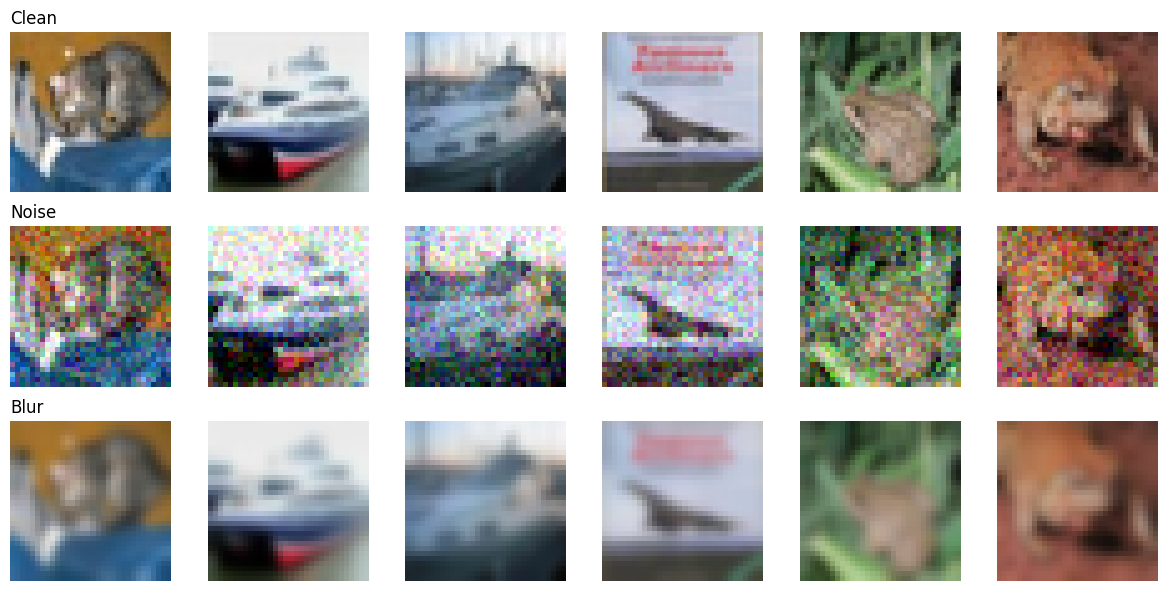

In [44]:
def make_noise(x, sigma, seed=0):
    g = torch.Generator().manual_seed(seed)
    return (x + torch.randn(x.shape, generator=g) * sigma).clamp(0, 1)

def make_blur(x, sigma, k=BLUR_KERNEL):
    out = [TF.gaussian_blur(x[i:i+1000], [k, k], [sigma, sigma]) for i in range(0, len(x), 1000)]
    return torch.cat(out)

x_noise = make_noise(x_clean, NOISE_SIGMA)
x_blur  = make_blur(x_clean, BLUR_SIGMA)
test_sets = {"Clean": x_clean, "Noise": x_noise, "Blur": x_blur}

# 視覺化檢查
fig, axes = plt.subplots(3, 6, figsize=(12, 6))
for j in range(6):
    for i, (name, xs) in enumerate(test_sets.items()):
        axes[i, j].imshow(xs[j].permute(1, 2, 0).numpy()); axes[i, j].axis("off")
        if j == 0: axes[i, j].set_title(name, loc="left")
plt.tight_layout(); plt.show()

In [45]:
class Normalize(nn.Module):
    def __init__(self, mean, std):
        super().__init__()
        self.register_buffer("mean", torch.tensor(mean).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor(std).view(1, 3, 1, 1))
    def forward(self, x):
        return (x - self.mean) / self.std

def conv_bn(i, o):
    return [nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=False)]

class CIFARNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.norm = Normalize(MEAN, STD)
        self.features = nn.Sequential(
            *conv_bn(3, 64),    *conv_bn(64, 64),    nn.MaxPool2d(2),   # 32 -> 16
            *conv_bn(64, 128),  *conv_bn(128, 128),  nn.MaxPool2d(2),   # 16 -> 8
            *conv_bn(128, 256), *conv_bn(256, 256),                      # 8x8, 最後一層 conv block
        )
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                  nn.Dropout(0.3), nn.Linear(256, num_classes))
    def forward(self, x):
        return self.head(self.features(self.norm(x)))

net = CIFARNet()
print(net)
print(f"Trainable parameters: {sum(p.numel() for p in net.parameters() if p.requires_grad):,}")

CIFARNet(
  (norm): Normalize()
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (8): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stri

In [46]:
def run_epoch(model, loader, opt=None, sched=None):
    train = opt is not None
    model.train(train)
    tot_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = F.cross_entropy(logits, y)
            if train:
                opt.zero_grad(set_to_none=True)
                loss.backward(); opt.step(); sched.step()
            tot_loss += loss.item() * len(y)
            correct  += (logits.argmax(1) == y).sum().item()
            n += len(y)
    return tot_loss / n, correct / n

def train_model(name, train_ds, weight_decay=0.0, epochs=EPOCHS, force=False):
    set_seed(SEED)
    model = CIFARNet().to(device)
    path = f"{CKPT_DIR}/{name}.pt"
    if os.path.exists(path) and not force:
        ck = torch.load(path, map_location=device)
        model.load_state_dict(ck["state"]); model.eval()
        print(f"[{name}] loaded checkpoint"); return model, ck["history"]

    loader = make_loader(train_ds, True)
    opt = torch.optim.SGD(model.parameters(), lr=LR, momentum=0.9, nesterov=True, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, epochs=epochs, steps_per_epoch=len(loader))
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_acc, best_state = 0.0, None
    for ep in range(1, epochs + 1):
        t0 = time.time()
        trl, tra = run_epoch(model, loader, opt, sched)
        vl, va   = run_epoch(model, val_loader)
        for k, v in zip(hist, (trl, tra, vl, va)): hist[k].append(v)
        if va > best_acc:
            best_acc = va; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"[{name}] ep {ep:02d}/{epochs} | train {trl:.3f}/{tra:.3f} | val {vl:.3f}/{va:.3f} | {time.time()-t0:.0f}s")
    model.load_state_dict(best_state); model.eval()
    torch.save({"state": best_state, "history": hist}, path)
    return model, hist

@torch.no_grad()
def predict(model, x, bs=1000):
    model.eval()
    return torch.cat([model(x[i:i+bs].to(device)).argmax(1).cpu() for i in range(0, len(x), bs)])

@torch.no_grad()
def evaluate_tensor(model, x, y, bs=1000):
    model.eval(); loss, correct = 0.0, 0
    for i in range(0, len(x), bs):
        out = model(x[i:i+bs].to(device)); yy = y[i:i+bs].to(device)
        loss += F.cross_entropy(out, yy, reduction="sum").item()
        correct += (out.argmax(1) == yy).sum().item()
    return loss / len(x), correct / len(x)

def plot_history(hist, title):
    ep = range(1, len(hist["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(ep, hist["train_loss"], label="train"); ax[0].plot(ep, hist["val_loss"], label="val")
    ax[0].set_title(f"{title} - Loss"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(ep, hist["train_acc"], label="train"); ax[1].plot(ep, hist["val_acc"], label="val")
    ax[1].set_title(f"{title} - Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()

[baseline] loaded checkpoint


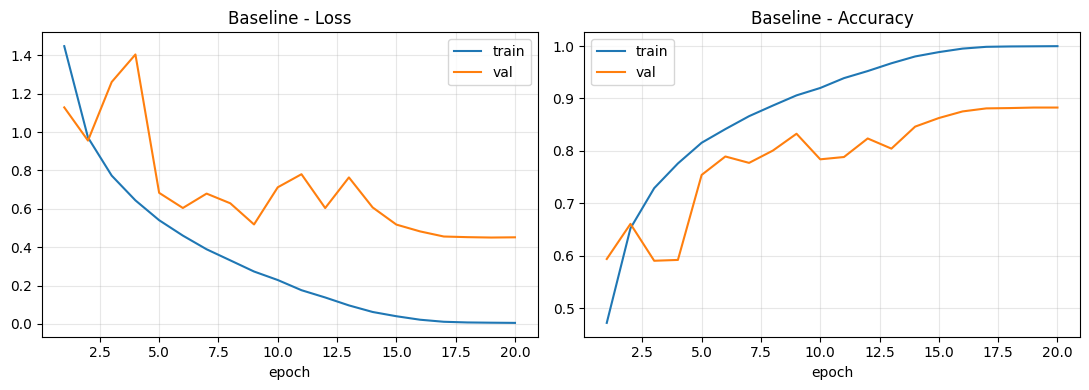

In [47]:
m_base, h_base = train_model("baseline", train_base_ds, weight_decay=0.0)
plot_history(h_base, "Baseline")

In [48]:
_, acc_clean = evaluate_tensor(m_base, x_clean, y_test)
print(f"Baseline test accuracy (clean): {acc_clean*100:.2f}%")

Baseline test accuracy (clean): 87.73%


In [49]:
for name, xs in test_sets.items():
    l, a = evaluate_tensor(m_base, xs, y_test)
    print(f"Baseline | {name:5s} | loss {l:.3f} | acc {a*100:.2f}%")

Baseline | Clean | loss 0.472 | acc 87.73%
Baseline | Noise | loss 4.007 | acc 35.79%
Baseline | Blur  | loss 3.268 | acc 37.42%


[l2] loaded checkpoint
[data_aug] loaded checkpoint


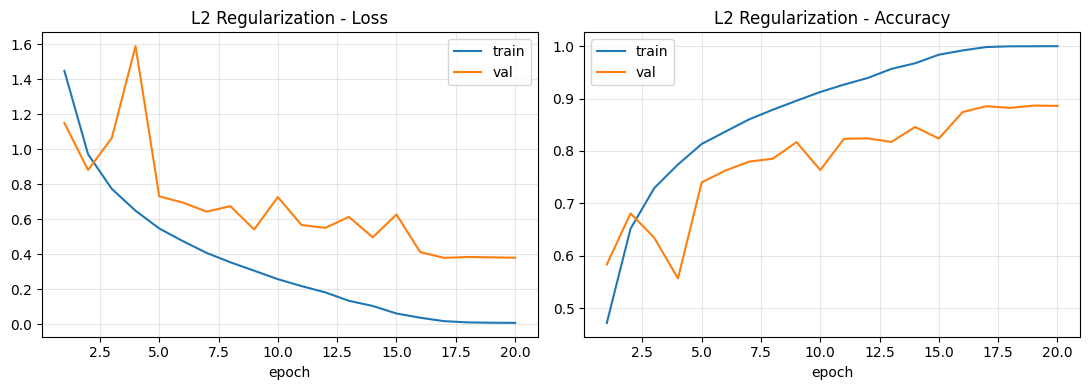

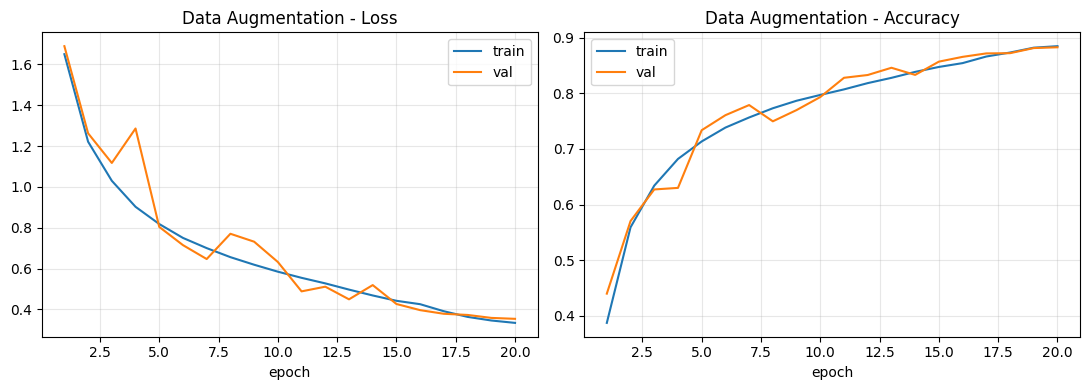

In [50]:
m_l2,  h_l2  = train_model("l2",       train_base_ds, weight_decay=WD_L2)
m_aug, h_aug = train_model("data_aug", train_aug_ds,  weight_decay=0.0)
plot_history(h_l2,  "L2 Regularization")
plot_history(h_aug, "Data Augmentation")

,Clean,Noise,Blur,Noise drop,Blur drop
Model,,,,,
Baseline CNN,87.73,35.79,37.42,51.94,50.31
L2 Regularization,88.57,39.51,36.13,49.06,52.44
Data Augmentation,87.58,81.16,82.76,6.42,4.82


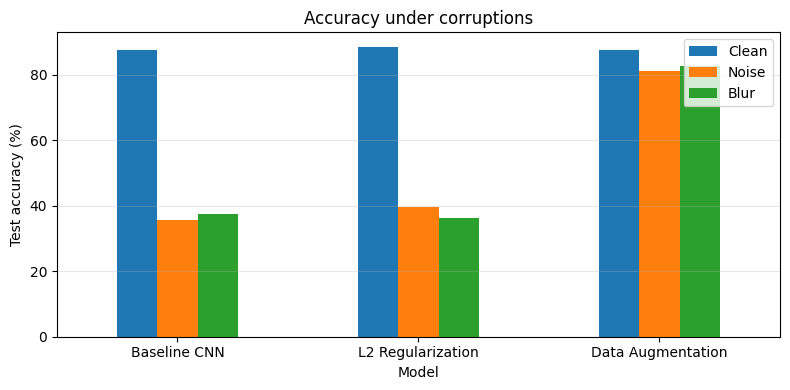

In [51]:
models = {"Baseline CNN": m_base, "L2 Regularization": m_l2, "Data Augmentation": m_aug}
rows = []
for n, m in models.items():
    rows.append({"Model": n, **{k: evaluate_tensor(m, x, y_test)[1] * 100 for k, x in test_sets.items()}})
df = pd.DataFrame(rows).set_index("Model").round(2)
df["Noise drop"] = (df["Clean"] - df["Noise"]).round(2)
df["Blur drop"]  = (df["Clean"] - df["Blur"]).round(2)
display(df)

ax = df[["Clean", "Noise", "Blur"]].plot(kind="bar", figsize=(8, 4), rot=0)
ax.set_ylabel("Test accuracy (%)"); ax.set_title("Accuracy under corruptions"); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

chosen test indices: [4, 1, 13]


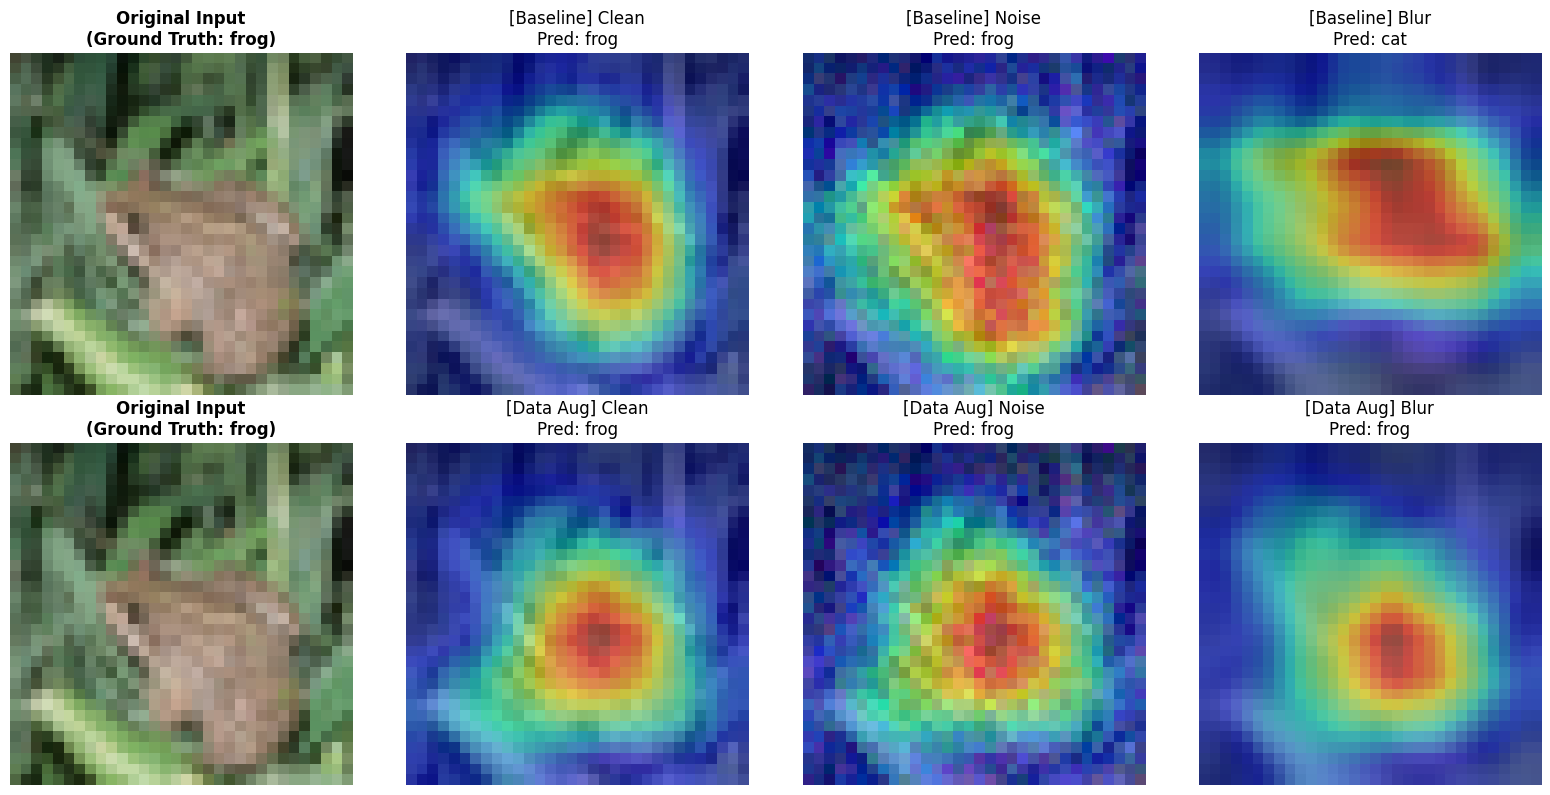

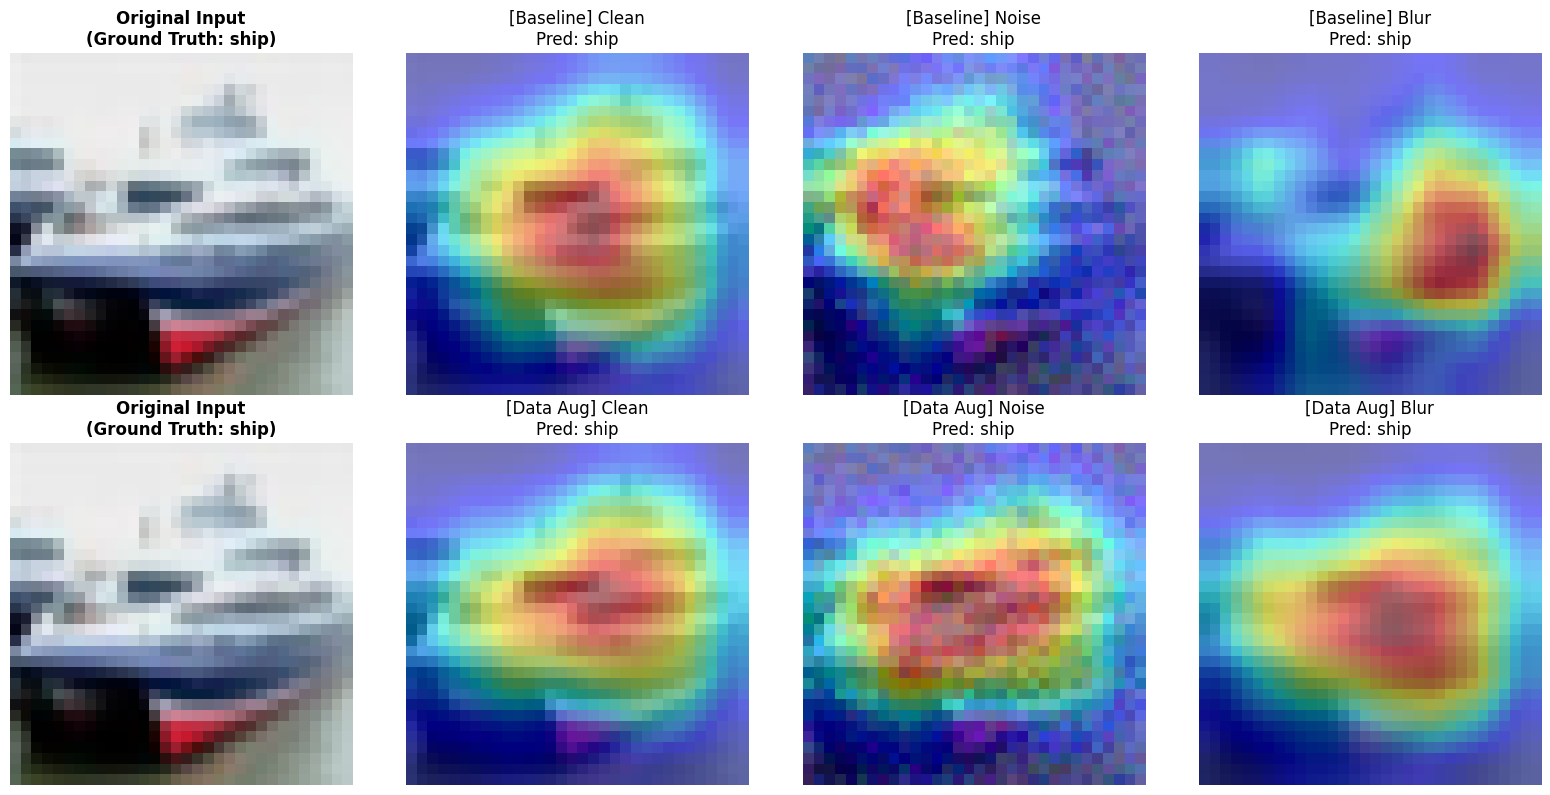

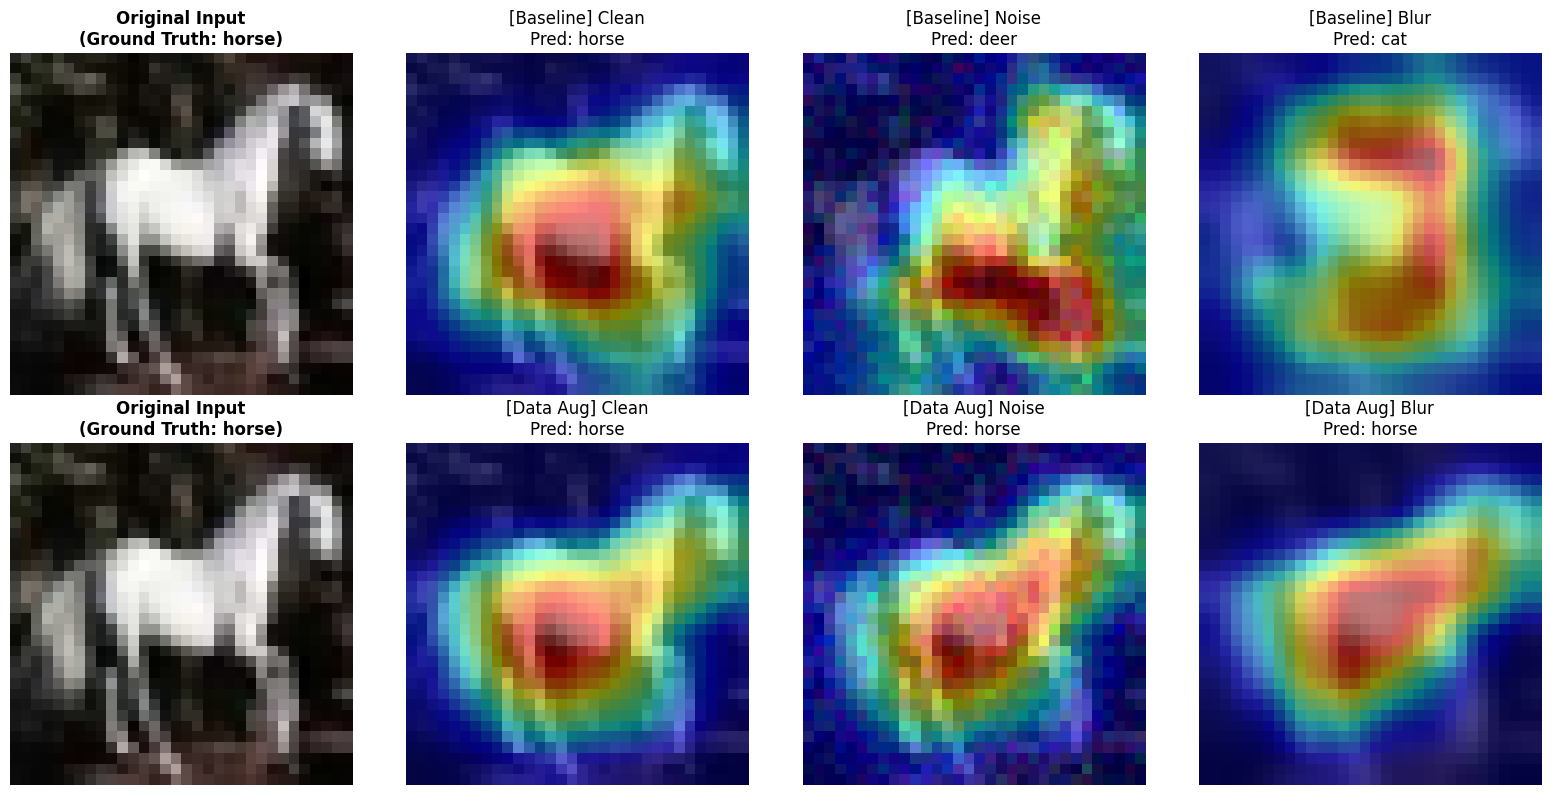

In [52]:
class GradCAM:
    """每次呼叫時才註冊 hook、算完立刻移除,不會影響平常的預測(含 no_grad),也不會累積舊 hook。"""
    def __init__(self, model, target_layer):
        self.model, self.layer = model, target_layer

    def __call__(self, x, target=None):
        self.model.eval()
        x = x.to(device)
        store = {}
        def fwd(module, inp, out):
            store["acts"] = out
            out.register_hook(lambda g: store.__setitem__("grads", g))
        handle = self.layer.register_forward_hook(fwd)
        try:
            with torch.enable_grad():
                logits = self.model(x)
                pred = logits.argmax(1)
                t = pred if target is None else target.to(device)
                self.model.zero_grad()
                logits.gather(1, t[:, None]).sum().backward()
        finally:
            handle.remove()
        acts, grads = store["acts"].detach(), store["grads"]
        w = grads.mean(dim=(2, 3), keepdim=True)                  # alpha_k
        cam = F.relu((w * acts).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
        cam = cam / (cam.amax(dim=(2, 3), keepdim=True) + 1e-8)
        return cam[:, 0].cpu(), pred.cpu()

# 清掉先前執行可能殘留的舊 hook
for _m in (m_base, m_aug):
    _m.features[-1]._forward_hooks.clear()
gc_base = GradCAM(m_base, m_base.features[-1])   # 最後一層 Conv-BN-ReLU 的輸出
gc_aug  = GradCAM(m_aug,  m_aug.features[-1])

def overlay(img_hwc, cam, alpha=0.5):
    heat = plt.cm.jet(cam)[..., :3]
    return np.clip((1 - alpha) * img_hwc + alpha * heat, 0, 1)

def plot_gradcam_comparison(idx, save_path=None):
    imgs = {k: v[idx:idx+1] for k, v in test_sets.items()}
    img0 = x_clean[idx].permute(1, 2, 0).numpy()
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    for r, (mname, gc) in enumerate([("Baseline", gc_base), ("Data Aug", gc_aug)]):
        axes[r, 0].imshow(img0)
        axes[r, 0].set_title(f"Original Input\n(Ground Truth: {CLASSES[y_test[idx]]})", fontweight="bold")
        for c, (cname, x) in enumerate(imgs.items(), start=1):
            cam, pred = gc(x)
            axes[r, c].imshow(overlay(x[0].permute(1, 2, 0).numpy(), cam[0].numpy()))
            axes[r, c].set_title(f"[{mname}] {cname}\nPred: {CLASSES[pred.item()]}")
        for a in axes[r]: a.axis("off")
    plt.tight_layout()
    if save_path: plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

pb, pa = predict(m_base, x_clean), predict(m_aug, x_clean)
chosen = []
for cname in ["frog", "ship", "horse"]:
    c = CLASSES.index(cname)
    cand = torch.where((y_test == c) & (pb == c) & (pa == c))[0]
    if len(cand): chosen.append(cand[0].item())
print("chosen test indices:", chosen)

for i in chosen:
    plot_gradcam_comparison(i, save_path=f"gradcam_idx{i}.png")

In [53]:
def cam_stability(gc, n=1000, bs=250):
    res = {"Noise": [], "Blur": []}
    for i in range(0, n, bs):
        xc = x_clean[i:i+bs]
        cam_c, pred_c = gc(xc)
        for name in res:
            cam_x, _ = gc(test_sets[name][i:i+bs], target=pred_c)
            a = cam_c.flatten(1); b = cam_x.flatten(1)
            a = a - a.mean(1, keepdim=True); b = b - b.mean(1, keepdim=True)
            corr = (a * b).sum(1) / (a.norm(dim=1) * b.norm(dim=1) + 1e-8)
            res[name].append(corr)
    return {k: torch.cat(v).mean().item() for k, v in res.items()}

stab = pd.DataFrame({"Baseline": cam_stability(gc_base), "Data Aug": cam_stability(gc_aug)}).T.round(3)
display(stab)

,Noise,Blur
Baseline,0.656,0.647
Data Aug,0.924,0.945


## (選做) 消融:只用 crop + flip,觀察對未見污染的效果

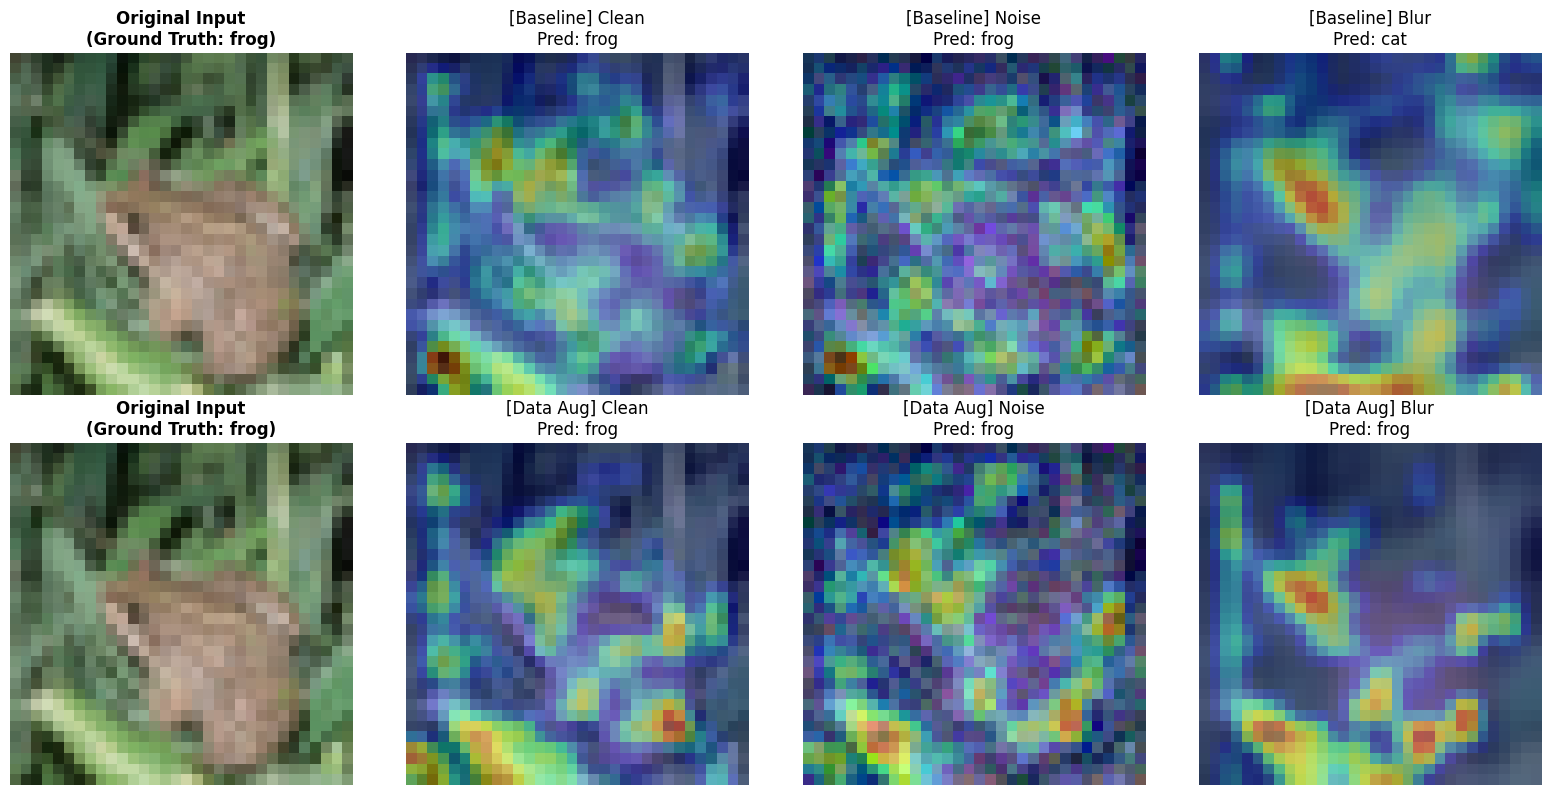

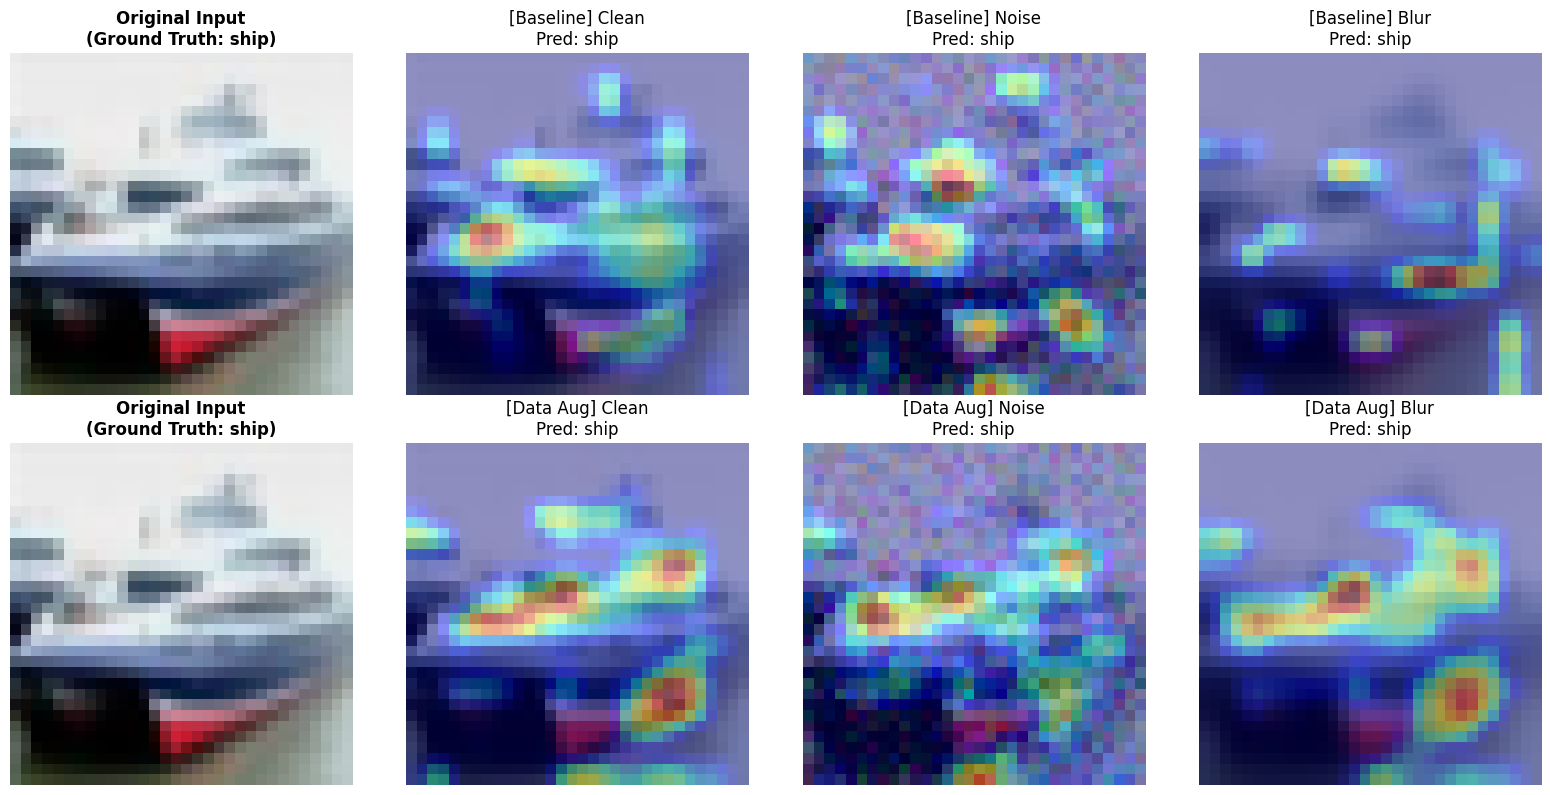

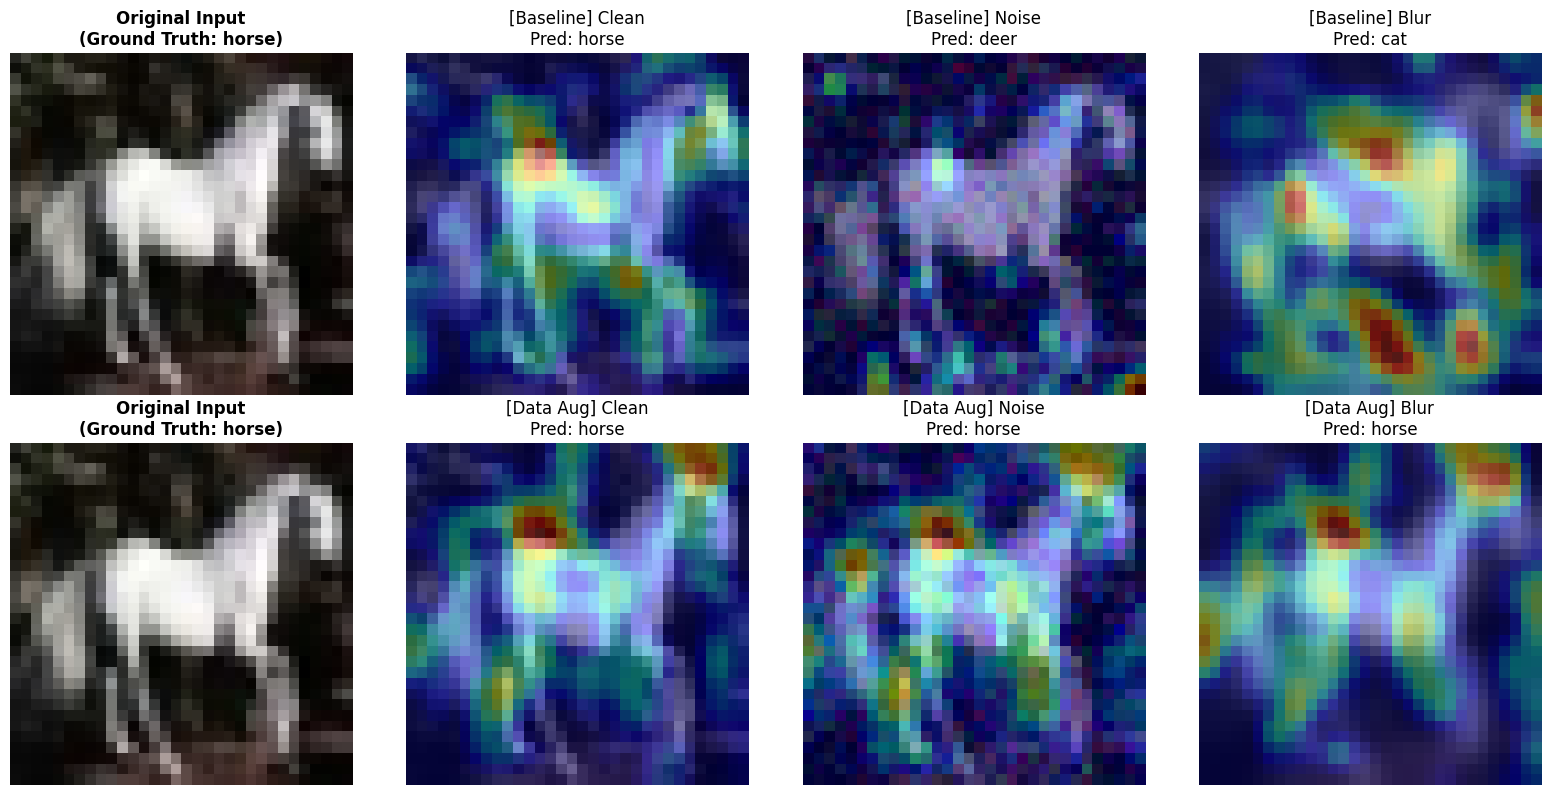

In [54]:
def plot_gradcam_fine(idx, layer_idx=12, alpha=0.4, save_path=None):
    g_b = GradCAM(m_base, m_base.features[layer_idx])
    g_a = GradCAM(m_aug,  m_aug.features[layer_idx])
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    for r, (mname, gc) in enumerate([("Baseline", g_b), ("Data Aug", g_a)]):
        axes[r, 0].imshow(x_clean[idx].permute(1, 2, 0).numpy(), interpolation="nearest")
        axes[r, 0].set_title(f"Original Input\n(Ground Truth: {CLASSES[y_test[idx]]})", fontweight="bold")
        for c, (cname, xs) in enumerate(test_sets.items(), start=1):
            x = xs[idx:idx+1]
            cam, pred = gc(x)
            axes[r, c].imshow(overlay(x[0].permute(1, 2, 0).numpy(), cam[0].numpy(), alpha),
                              interpolation="nearest")
            axes[r, c].set_title(f"[{mname}] {cname}\nPred: {CLASSES[pred.item()]}")
        for a in axes[r]: a.axis("off")
    plt.tight_layout()
    if save_path: plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

for i in [4, 1, 13]:
    plot_gradcam_fine(i, save_path=f"gradcam_fine_idx{i}.png")